Publication adaptation: workspace labels and runtime paths have been renamed. Saved scientific results and embedded image bytes are retained from the recorded run; this source notebook has not been recomputed after that adaptation. Printed historical checksums describe that recorded run. Current released-file checksums are in the publication source map.

# MC3 branch-restricted state differences with joint family uncertainty

## Context and prespecified scope
This companion independently checks the core state arithmetic and then estimates mutant-minus-WT mean pseudotime among MC3 cells carrying each of the five existing overlapping Palantir branch masks. This is a branch-restricted observed-state association, not differentiation speed, individual-cell reversal, branch entry, or a direct comparison of mutations. The prior reference branch analysis was cell-weighted and sample-by-replicate-stratified; exact agreement with those older estimates is neither expected nor claimed. Here, biological replicate and sex are excluded from analytical stratification as requested.

One family mean is calculated within each sample and arm among cells on the specified branch. Contributing samples need two family rows in each arm, with original point-estimation eligibility requiring at least ten cells and three family/sample rows per arm. Sample weights are fixed at the observed minimum arm family count divided by its sum. Inferential support requires five distinct families per arm and ten in their union. The branch family consists of all **20 planned tests**: five branches × two days × two mutations. Unsupported tests remain missing in results and count as P=1 only in the BH denominator. No arm-departure or between-branch contrast is tested.

### Family influence and interpretation
With fixed sample weights $a_s$, arm means $\bar y_{as}$, and arm/sample family counts $n_{as}$,
$\hat\Delta=\sum_s a_s(\bar y_{ms}-\bar y_{ws})$.
Family $g$ contributes
$u_g=\sum_s a_s[\sum_{i\in(g,m,s)}(y_i-\bar y_{ms})/n_{ms}-\sum_{i\in(g,w,s)}(y_i-\bar y_{ws})/n_{ws}]$.
Its contributions are summed across every sample and arm before uncertainty is calculated. The estimated variance is $G/(G-1)\sum_g u_g^2$. A Rademacher multiplier is shared by all records of the same family; 9,999 draws approximate the centered sampling distribution. Two-sided P values are conditional asymptotic multiplier estimates, not exact randomization P values. Intervals are pointwise 95% cluster-sandwich t intervals with G−1 degrees of freedom, not multiplicity-adjusted intervals. Small arm support, fixed reference partition, observed recovery and sequencing-sample weighting limit generalization.

Environment: existing **chronoclone**, existing Conda-compatible installation `/path/to/ChronoClone/.runtime/chronoclone`; kernel `chronoclone`. No packages are installed or modified. Versions and exact execution command are printed in the first code cell. The three panels are generated separately, one complete inline plotting cell and one SVG/PNG stem per plot.


In [1]:

from pathlib import Path
import sys,json,hashlib,platform,importlib.metadata as metadata
import numpy as np,pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy import stats
from statsmodels.stats.multitest import multipletests
from IPython.display import display
O=Path('/path/to/ChronoClone/analysis_workspace/singh/singh_reference_response_20260911/dynamics')
ROOT=O.parents[3]
runner=ROOT/'analysis_workspace/manuscript/chronoclone_panel_revision_20260910/execute_notebook.py'
environment={'environment':'chronoclone','path':str(Path(sys.executable).parent.parent),'kernel':'chronoclone','Python':platform.python_version(),'versions':{p:metadata.version(p) for p in ['numpy','pandas','scipy','statsmodels','matplotlib','nbformat']},'execution_command':f'{sys.executable} {runner} {O/"0002_mc3_branch_responses.ipynb"}'}
assert environment['path']=='/path/to/ChronoClone/.runtime/chronoclone'
display(environment)
inputs=[O/'tables/cells_resolved.csv',O/'tables/clone_arm_table.csv',O/'tables/effects.csv',O/'0001_family_aware_responses.ipynb',O.parent/'build_core_notebook.py']
hashes={str(p.relative_to(ROOT)):hashlib.sha256(p.read_bytes()).hexdigest() for p in inputs}
pd.DataFrame([{'path':p,'sha256':h} for p,h in hashes.items()]).to_csv(O/'reports/branch_input_manifest.csv',index=False)
D=pd.read_csv(O/'tables/cells_resolved.csv',dtype={'mc':str,'clone':str})
CA=pd.read_csv(O/'tables/clone_arm_table.csv',dtype={'mc':str,'clone':str})
E=pd.read_csv(O/'tables/effects.csv',dtype={'mc':str})
assert D.clone.notna().all() and D.groupby('clone').mc.nunique().max()==1
assert not CA.duplicated(['mc','day','arm','stratum','clone']).any()
BRANCHES=['Mk','Ery','Baso','Neu','Mono'];NAMES={'Mk':'Megakaryocyte','Ery':'Erythroid','Baso':'Basophil','Neu':'Neutrophil','Mono':'Monocyte'}
MUTANTS=['Dnmt3a','Npm1c'];COLORS={'Dnmt3a':'#2878B5','Npm1c':'#D55E00'}
plt.rcParams.update({'svg.fonttype':'none','font.family':'Arial','font.size':14,'axes.labelsize':15,'xtick.labelsize':13,'ytick.labelsize':14,'axes.spines.top':False,'axes.spines.right':False,'figure.dpi':110})
print('Resolved lineage families:',D.clone.nunique(),'Day7 families:',D.loc[D.day.eq('D7'),'clone'].nunique())


{'environment': 'chronoclone',
 'path': '/path/to/ChronoClone/.runtime/chronoclone',
 'kernel': 'chronoclone',
 'Python': '3.11.15',
 'versions': {'numpy': '2.4.6',
  'pandas': '2.3.3',
  'scipy': '1.17.1',
  'statsmodels': '0.14.6',
  'matplotlib': '3.11.0',
  'nbformat': '5.10.4'},
 'execution_command': '/path/to/ChronoClone/.runtime/chronoclone/bin/python /path/to/ChronoClone/analysis_workspace/manuscript/chronoclone_panel_revision_20260910/execute_notebook.py /path/to/ChronoClone/analysis_workspace/singh/singh_reference_response_20260911/dynamics/0002_mc3_branch_responses.ipynb'}

Resolved lineage families: 1516 Day7 families: 1514


In [2]:

def scalar_family_fit(sub,mutant,seed=20260911,draws=9999):
    # Independent scalar implementation of the core fixed-weight estimator.
    rec={'point_estimable':False,'inference_estimable':False,'dpsi':np.nan,'se':np.nan,'ci_low':np.nan,'ci_high':np.nan,'p':np.nan,'reason':'','cells_wt':int(sub.loc[sub.arm.eq('WT'),'n'].sum()),'cells_mut':int(sub.loc[sub.arm.eq(mutant),'n'].sum()),'rows_wt':int(sub.arm.eq('WT').sum()),'rows_mut':int(sub.arm.eq(mutant).sum())}
    if min(rec['cells_wt'],rec['cells_mut'])<10 or min(rec['rows_wt'],rec['rows_mut'])<3:
        rec['reason']='insufficient observed cells or family/sample rows';return rec,pd.DataFrame(),pd.DataFrame()
    eligible=[]
    for sample,g in sub.groupby('stratum',observed=True):
        w=g.loc[g.arm.eq('WT')];m=g.loc[g.arm.eq(mutant)]
        if len(w)>=2 and len(m)>=2:eligible.append((sample,w,m,min(len(w),len(m))))
    if not eligible:
        rec['reason']='no sample with both arms';return rec,pd.DataFrame(),pd.DataFrame()
    denominator=sum(z[3] for z in eligible);contributions=[];sample_rows=[];delta=0.
    for sample,w,m,support in eligible:
        a=support/denominator;diff=m.psi.mean()-w.psi.mean();delta+=a*diff
        sample_rows.append({'sample':sample,'weight':a,'dpsi':diff,'families_wt':len(w),'families_mut':len(m),'cells_wt':int(w.n.sum()),'cells_mut':int(m.n.sum())})
        for frame,sign in [(w,-1),(m,1)]:
            residual=sign*a*(frame.psi-frame.psi.mean())/len(frame)
            contributions.extend({'clone':c,'influence':v} for c,v in zip(frame.clone,residual))
    influence=pd.DataFrame(contributions).groupby('clone',sort=True).influence.sum()
    fw=set().union(*[set(w.clone) for _,w,_,_ in eligible]);fm=set().union(*[set(m.clone) for _,_,m,_ in eligible]);G=len(influence)
    assert G==len(fw|fm) and abs(influence.sum())<1e-10
    rec.update(point_estimable=True,dpsi=delta,n_samples=len(eligible),families_wt=len(fw),families_mut=len(fm),families_union=G,families_shared=len(fw&fm))
    if min(len(fw),len(fm))<5 or G<10:
        rec['reason']='fewer than five families in an arm or ten in union';return rec,pd.DataFrame(sample_rows),influence.to_frame()
    scaled=influence.to_numpy()*np.sqrt(G/(G-1));se=np.linalg.norm(scaled)
    if se<=1e-12:
        rec['reason']='zero state influence variance';return rec,pd.DataFrame(sample_rows),influence.to_frame()
    rng=np.random.default_rng(seed);null=rng.choice(np.array([-1.,1.]),size=(draws,G))@scaled
    p=(1+np.count_nonzero(np.abs(null/se)>=abs(delta/se)))/(draws+1)
    crit=stats.t.ppf(.975,G-1)
    rec.update(inference_estimable=True,se=se,ci_low=delta-crit*se,ci_high=delta+crit*se,p=p)
    return rec,pd.DataFrame(sample_rows),influence.to_frame()

# Recompute the already performed core state estimator; this is verification, not an additional test family.
checks=[]
for i,r in E.iterrows():
    sub=CA.loc[CA.mc.eq(r.mc)&CA.day.eq(r.day)&CA.arm.isin(['WT',r.mutant])]
    fit,_,_=scalar_family_fit(sub,r.mutant,seed=20260911+i)
    assert fit['point_estimable']==r.point_estimable and fit['inference_estimable']==r.inference_estimable
    for current,saved in [('dpsi','dpsi'),('se','se'),('ci_low','ci_low'),('ci_high','ci_high'),('p','p_state')]:
        assert np.isclose(fit[current],r[saved],atol=1e-12,equal_nan=True),(i,current,fit[current],r[saved])
    checks.append({'mc':r.mc,'day':r.day,'mutant':r.mutant,'point_reproduced':bool(r.point_estimable),'inference_reproduced':bool(r.inference_estimable)})
for endpoint in ['state','composition']:
    expected=multipletests(E['p_'+endpoint].fillna(1),method='fdr_bh')[1]
    ok=E['p_'+endpoint].notna()
    assert np.allclose(expected[ok],E.loc[ok,'q_'+endpoint]) and E.loc[~ok,'q_'+endpoint].isna().all()
pd.DataFrame(checks).to_csv(O/'reports/independent_core_state_check.csv',index=False)
print('Core state points, SE, intervals and multiplier P values independently reproduced:',pd.DataFrame(checks).sum(numeric_only=True).to_dict())
print('Both fixed 68-test BH families reproduced.')

# Paired covariance and repeated-row check: identical paired values cancel, even across two samples.
toy=pd.DataFrame([{'clone':str(i),'stratum':s,'arm':a,'n':3,'psi':i/20+(s=='s2')*.1} for i in range(12) for s in ['s1','s2'] for a in ['WT','Dnmt3a']])
fit,_,inf=scalar_family_fit(toy,'Dnmt3a')
assert np.allclose(inf.influence,0) and abs(fit['dpsi'])<1e-12 and fit['reason']=='zero state influence variance'
print('Repeated cross-arm family covariance cancellation verified.')


Core state points, SE, intervals and multiplier P values independently reproduced: {'point_reproduced': 33, 'inference_reproduced': 29}
Both fixed 68-test BH families reproduced.
Repeated cross-arm family covariance cancellation verified.


## Branch results
Existing overlapping branch masks are used verbatim. A cell can contribute to more than one branch, so the branch support counts must not be summed. Each branch mean is computed from its own qualifying family rows; differing support across branches is reported, not hidden.

In [3]:

records=[];sample_support=[];branch_rows=[]
for day in ['D14','D27']:
    for mutant in MUTANTS:
        for branch in BRANCHES:
            selected=D.loc[D.mc.eq('3')&D.day.eq(day)&D.arm.isin(['WT',mutant])&D['mask_'+branch].eq(True)]
            rows=selected.groupby(['mc','day','arm','stratum','clone'],observed=True).agg(n=('psi','size'),psi=('psi','mean')).reset_index()
            key={'mc':'3','day':day,'mutant':mutant,'branch':branch}
            fit,ss,inf=scalar_family_fit(rows,mutant,seed=20261100+len(records))
            records.append(key|fit)
            sample_support.extend(key|r for r in ss.to_dict('records'))
            branch_rows.extend(key|r for r in rows.to_dict('records'))
B=pd.DataFrame(records);assert len(B)==20
q=multipletests(B.p.fillna(1),method='fdr_bh')[1];B['q_20']=np.where(B.p.notna(),q,np.nan)
B['minimum_arm_families']=B[['families_wt','families_mut']].min(axis=1)
B.to_csv(O/'tables/mc3_branch_effects.csv',index=False)
pd.DataFrame(sample_support).to_csv(O/'tables/mc3_branch_sample_support.csv',index=False)
pd.DataFrame(branch_rows).to_csv(O/'tables/mc3_branch_family_rows.csv',index=False)
display(B[['day','mutant','branch','dpsi','ci_low','ci_high','q_20','families_wt','families_mut','families_shared','reason']])
display(B.groupby(['day','mutant'])[['point_estimable','inference_estimable']].sum())


,day,mutant,branch,dpsi,ci_low,ci_high,q_20,families_wt,families_mut,families_shared,reason
0,D14,Dnmt3a,Mk,-0.080442,-0.258091,0.097206,0.564800,38,14,10,
1,D14,Dnmt3a,Ery,0.030029,-0.126006,0.186064,0.750600,33,14,6,
2,D14,Dnmt3a,Baso,0.044652,-0.100100,0.189404,0.651765,30,14,6,
3,D14,Dnmt3a,Neu,0.064077,-0.004268,0.132421,0.110182,94,32,31,
4,D14,Dnmt3a,Mono,0.046868,-0.022019,0.115755,0.300333,94,31,30,
5,D14,Npm1c,Mk,-0.360102,-0.508191,-0.212013,0.000250,38,11,5,
6,D14,Npm1c,Ery,-0.309152,-0.433398,-0.184906,0.000250,33,11,4,
7,D14,Npm1c,Baso,-0.262449,-0.390968,-0.133930,0.000250,30,11,4,
8,D14,Npm1c,Neu,-0.026508,-0.091014,0.037998,0.564800,94,17,17,
9,D14,Npm1c,Mono,-0.027322,-0.092130,0.037487,0.564800,94,17,17,


point_estimable  inference_estimable
day mutant                                      
D14 Dnmt3a                5                    5
    Npm1c                 5                    5
D27 Dnmt3a                5                    5
    Npm1c                 5                    5

## Raw manuscript panels
The forest plots share scales and visual encodings. Stars denote the single 20-test branch family: ** q<0.05; * 0.05≤q<0.10. Intervals remain unadjusted pointwise intervals. Unsupported point estimates, if any, use hollow markers without intervals.

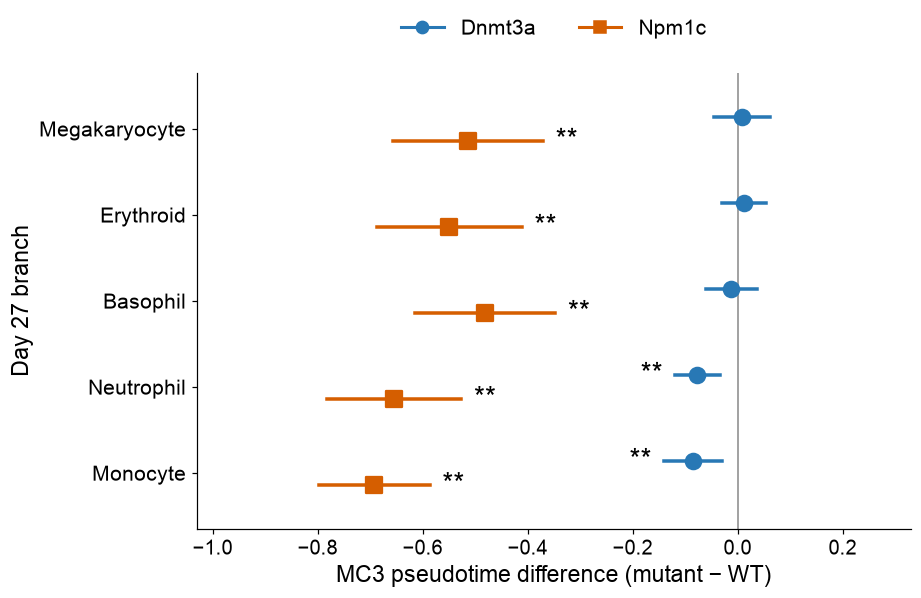

/path/to/ChronoClone/analysis_workspace/singh/singh_reference_response_20260911/dynamics/panels/figure_5f_mc3_day27_branch_state


In [4]:

plot=B.loc[B.day.eq('D27')].copy();plot['position']=plot.branch.map({b:i for i,b in enumerate(BRANCHES)})
fig,ax=plt.subplots(figsize=(8.6,5.7));ax.axvline(0,color='#888888',lw=1)
for row in plot.itertuples():
    y=row.position+(-.14 if row.mutant=='Dnmt3a' else .14);marker='o' if row.mutant=='Dnmt3a' else 's'
    if row.inference_estimable:ax.plot([row.ci_low,row.ci_high],[y,y],color=COLORS[row.mutant],lw=2.3)
    if row.point_estimable:ax.scatter(row.dpsi,y,s=100,marker=marker,edgecolor=COLORS[row.mutant],facecolor=COLORS[row.mutant] if row.inference_estimable else 'white',linewidth=1.5,zorder=3)
    if pd.notna(row.q_20) and row.q_20<.1:
        label_x=row.ci_high+.024;near_zero=(-.055<label_x<.035)
        ax.text(row.ci_low-.024 if near_zero else label_x,y,'**' if row.q_20<.05 else '*',va='center',ha='right' if near_zero else 'left',fontsize=18)
ax.set_yticks(range(5),[NAMES[b] for b in BRANCHES]);ax.invert_yaxis();ax.set_ylim(4.65,-.65);ax.set_xlim(-1.03,.33)
ax.set_xlabel('MC3 pseudotime difference (mutant − WT)');ax.set_ylabel('Day 27 branch')
handles=[Line2D([],[],color=COLORS[a],marker='o' if a=='Dnmt3a' else 's',lw=2,markersize=8,label=a) for a in MUTANTS]
ax.legend(handles=handles,frameon=False,loc='upper center',bbox_to_anchor=(.5,1.16),ncol=2)
fig.tight_layout();stem=O/'panels/figure_5f_mc3_day27_branch_state';fig.savefig(stem.with_suffix('.svg'),bbox_inches='tight');fig.savefig(stem.with_suffix('.png'),dpi=220,bbox_inches='tight');plt.show();print(stem)


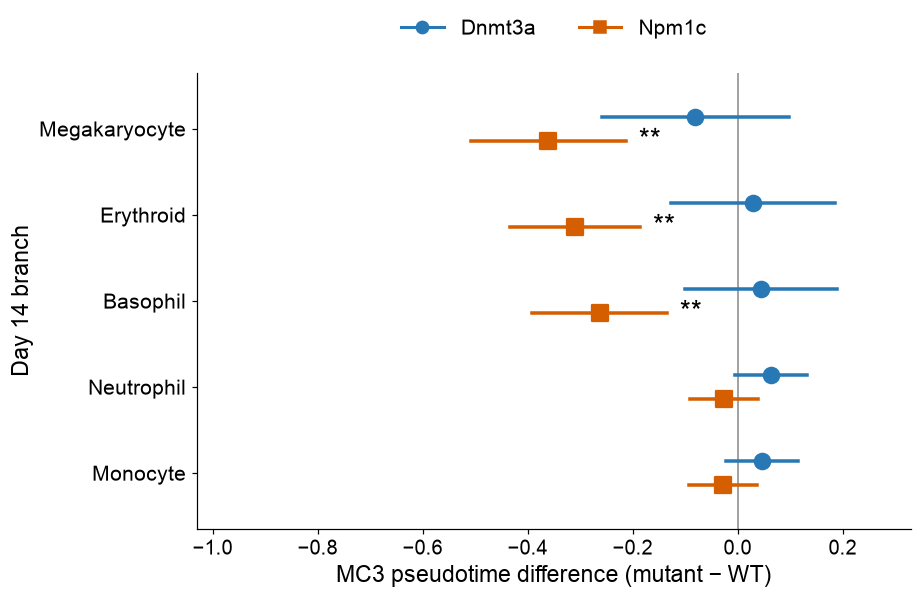

/path/to/ChronoClone/analysis_workspace/singh/singh_reference_response_20260911/dynamics/panels/figure_s6b_mc3_day14_branch_state


In [5]:

plot=B.loc[B.day.eq('D14')].copy();plot['position']=plot.branch.map({b:i for i,b in enumerate(BRANCHES)})
fig,ax=plt.subplots(figsize=(8.6,5.7));ax.axvline(0,color='#888888',lw=1)
for row in plot.itertuples():
    y=row.position+(-.14 if row.mutant=='Dnmt3a' else .14);marker='o' if row.mutant=='Dnmt3a' else 's'
    if row.inference_estimable:ax.plot([row.ci_low,row.ci_high],[y,y],color=COLORS[row.mutant],lw=2.3)
    if row.point_estimable:ax.scatter(row.dpsi,y,s=100,marker=marker,edgecolor=COLORS[row.mutant],facecolor=COLORS[row.mutant] if row.inference_estimable else 'white',linewidth=1.5,zorder=3)
    if pd.notna(row.q_20) and row.q_20<.1:
        label_x=row.ci_high+.024;near_zero=(-.055<label_x<.035)
        ax.text(row.ci_low-.024 if near_zero else label_x,y,'**' if row.q_20<.05 else '*',va='center',ha='right' if near_zero else 'left',fontsize=18)
ax.set_yticks(range(5),[NAMES[b] for b in BRANCHES]);ax.invert_yaxis();ax.set_ylim(4.65,-.65);ax.set_xlim(-1.03,.33)
ax.set_xlabel('MC3 pseudotime difference (mutant − WT)');ax.set_ylabel('Day 14 branch')
handles=[Line2D([],[],color=COLORS[a],marker='o' if a=='Dnmt3a' else 's',lw=2,markersize=8,label=a) for a in MUTANTS]
ax.legend(handles=handles,frameon=False,loc='upper center',bbox_to_anchor=(.5,1.16),ncol=2)
fig.tight_layout();stem=O/'panels/figure_s6b_mc3_day14_branch_state';fig.savefig(stem.with_suffix('.svg'),bbox_inches='tight');fig.savefig(stem.with_suffix('.png'),dpi=220,bbox_inches='tight');plt.show();print(stem)


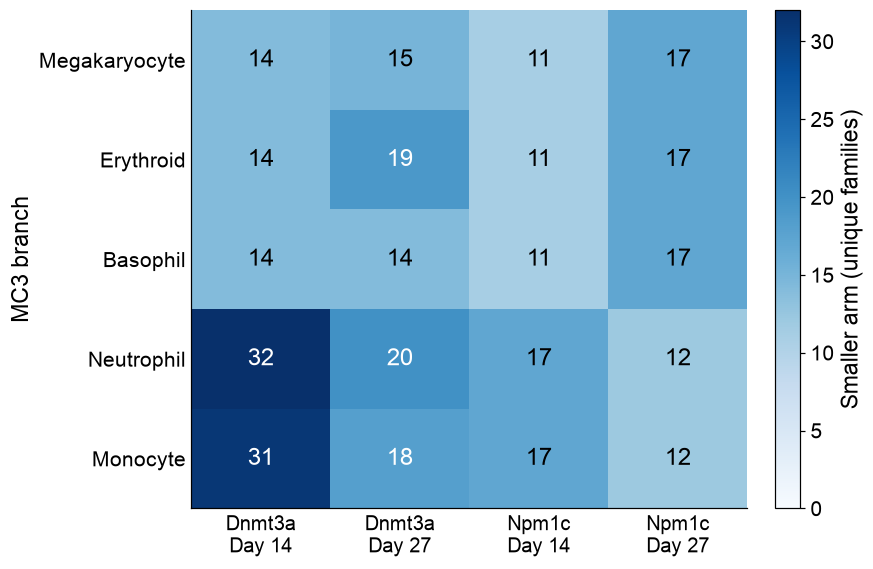

/path/to/ChronoClone/analysis_workspace/singh/singh_reference_response_20260911/dynamics/panels/figure_s6c_mc3_branch_support


In [6]:

columns=[('Dnmt3a','D14'),('Dnmt3a','D27'),('Npm1c','D14'),('Npm1c','D27')]
support=B.pivot(index='branch',columns=['mutant','day'],values='minimum_arm_families').reindex(index=BRANCHES,columns=columns)
fig,ax=plt.subplots(figsize=(8.3,5.4));cmap=plt.get_cmap('Blues').copy();cmap.set_bad('#e6e6e6')
image=ax.imshow(support.values,cmap=cmap,vmin=0,vmax=max(10,float(np.nanmax(support.values))),aspect='auto')
for i in range(5):
    for j in range(4):
        value=support.iloc[i,j]
        if pd.notna(value):ax.text(j,i,str(int(value)),ha='center',va='center',fontsize=16,color='white' if value>float(np.nanmax(support.values))*.55 else 'black')
ax.set_xticks(range(4),['Dnmt3a\nDay 14','Dnmt3a\nDay 27','Npm1c\nDay 14','Npm1c\nDay 27']);ax.set_yticks(range(5),[NAMES[b] for b in BRANCHES]);ax.tick_params(length=0)
ax.set_ylabel('MC3 branch');colorbar=fig.colorbar(image,ax=ax,pad=.04);colorbar.set_label('Smaller arm (unique families)')
fig.tight_layout();stem=O/'panels/figure_s6c_mc3_branch_support';fig.savefig(stem.with_suffix('.svg'),bbox_inches='tight');fig.savefig(stem.with_suffix('.png'),dpi=220,bbox_inches='tight');plt.show();print(stem)


In [7]:

assert all(hashlib.sha256((ROOT/p).read_bytes()).hexdigest()==h for p,h in hashes.items())
import nbformat,ast
source_notebook=nbformat.read(O/'0002_mc3_branch_responses.ipynb',as_version=4)
plot_cells=[c for c in source_notebook.cells if c.cell_type=='code' and any(isinstance(n,ast.Call) and isinstance(n.func,ast.Attribute) and isinstance(n.func.value,ast.Name) and n.func.value.id=='plt' and n.func.attr=='subplots' for n in ast.walk(ast.parse(c.source)))]
assert len(plot_cells)==3
for c in plot_cells:
    assert c.source.count('plt.subplots(')==1 and c.source.count("stem.with_suffix('.svg')")==1 and 'plt.show()' in c.source
    assert ('plot=B.loc' in c.source or 'support=B.pivot' in c.source) and '.set_title(' not in c.source
print('Three inline plot cells; one figure and one SVG stem in each; no panel titles.')
summary={'planned_branch_tests':len(B),'point_estimable':int(B.point_estimable.sum()),'inference_estimable':int(B.inference_estimable.sum()),'q_lt_005':int(B.q_20.lt(.05).sum()),'q_lt_010':int(B.q_20.lt(.1).sum()),'source_hashes_unchanged':True,'core_points_reproduced':int(E.point_estimable.sum()),'core_inferences_reproduced':int(E.inference_estimable.sum()),'environment':environment,'panel_stems':['figure_5f_mc3_day27_branch_state','figure_s6b_mc3_day14_branch_state','figure_s6c_mc3_branch_support']}
(O/'reports/branch_results_summary.json').write_text(json.dumps(summary,indent=2))
display(summary)


Three inline plot cells; one figure and one SVG stem in each; no panel titles.


{'planned_branch_tests': 20,
 'point_estimable': 20,
 'inference_estimable': 20,
 'q_lt_005': 10,
 'q_lt_010': 10,
 'source_hashes_unchanged': True,
 'core_points_reproduced': 33,
 'core_inferences_reproduced': 29,
 'environment': {'environment': 'chronoclone',
  'path': '/path/to/ChronoClone/.runtime/chronoclone',
  'kernel': 'chronoclone',
  'Python': '3.11.15',
  'versions': {'numpy': '2.4.6',
   'pandas': '2.3.3',
   'scipy': '1.17.1',
   'statsmodels': '0.14.6',
   'matplotlib': '3.11.0',
   'nbformat': '5.10.4'},
  'execution_command': '/path/to/ChronoClone/.runtime/chronoclone/bin/python /path/to/ChronoClone/analysis_workspace/manuscript/chronoclone_panel_revision_20260910/execute_notebook.py /path/to/ChronoClone/analysis_workspace/singh/singh_reference_response_20260911/dynamics/0002_mc3_branch_responses.ipynb'},
 'panel_stems': ['figure_5f_mc3_day27_branch_state',
  'figure_s6b_mc3_day14_branch_state',
  'figure_s6c_mc3_branch_support']}